## Multivariate Time-Series Forecasting with Transformer Neural Network  
Done by: Chamath Wijerathne, Nada Rahali, Tanjuma Haque

In [59]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random
import kagglehub
from sklearn.preprocessing import MinMaxScaler
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

In [60]:
plt.style.use("seaborn-v0_8")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cpu')

## Data loading and preprocessing

In [61]:
path = kagglehub.dataset_download("uciml/electric-power-consumption-data-set")
print("Path to dataset files:", path)

file_path = os.path.join(path, "household_power_consumption.txt")

df = pd.read_csv(
    file_path,
    sep=";",
    na_values="?",
    low_memory=False
)

df["DateTime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"], format="%d/%m/%Y %H:%M:%S"
)
df = df.set_index("DateTime")
df = df.drop(columns=["Date", "Time"])

df.head()

Path to dataset files: C:\Users\anura\.cache\kagglehub\datasets\uciml\electric-power-consumption-data-set\versions\1


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
DateTime,,,,,,,
2006-12-16 17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
2006-12-16 17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2006-12-16 17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
2006-12-16 17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
2006-12-16 17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


### Preview of the Loaded Dataset

The table above shows the first few rows of the **minute level household power consumption data** after loading and preprocessing the file.

Each row corresponds to a single timestamp, and the index is now the combined **DateTime** column created from the original `Date` and `Time` fields.

The columns shown include:

- **Global_active_power (kW)** – total active power consumed by the household at that minute  
- **Global_reactive_power (kVAR)** – reactive (non-working) power  
- **Voltage (V)** – average voltage during the minute  
- **Global_intensity (A)** – average current  
- **Sub_metering_1, Sub_metering_2, Sub_metering_3 (Wh)** – energy usage recorded by three separate household sub-meters

This preview confirms that:
1. The dataset was loaded correctly from the Kaggle directory.  
2. Missing values were recognized as `"?"` and converted to `NaN`.  
3. `Date` and `Time` were successfully merged into a single `DateTime` index.  
4. The dataset is now ready for cleaning, resampling, scaling, and model preparation.

In [62]:
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Total missing values:", df.isna().sum().sum())

df = df.interpolate()

print("Missing values after interpolation:", df.isna().sum().sum())

df["y"] = (
    df["Global_active_power"] * 1000 / 60
    - df["Sub_metering_1"]
    - df["Sub_metering_2"]
    - df["Sub_metering_3"]
)

df[["Global_active_power", "Sub_metering_1", "Sub_metering_2", "Sub_metering_3", "y"]].head()


Total missing values: 181853
Missing values after interpolation: 0


,Global_active_power,Sub_metering_1,Sub_metering_2,Sub_metering_3,y
DateTime,,,,,
2006-12-16 17:24:00,4.216,0.0,1.0,17.0,52.266667
2006-12-16 17:25:00,5.360,0.0,1.0,16.0,72.333333
2006-12-16 17:26:00,5.374,0.0,2.0,17.0,70.566667
2006-12-16 17:27:00,5.388,0.0,1.0,17.0,71.800000
2006-12-16 17:28:00,3.666,0.0,1.0,17.0,43.100000


The code converts all dataset columns to numeric format, automatically treating non-numeric entries such as `"?"` as missing values. After this conversion, the dataset is found to contain a substantial number of missing values, which are handled using time-based linear interpolation to preserve the temporal continuity of the series. Following interpolation, no missing values remain, ensuring the data is suitable for sequence-based neural network training. A new target variable `y` is then computed to represent unmeasured household energy consumption by subtracting the energy recorded by the three sub-meters from the total active power consumption. The resulting dataset preview confirms that the preprocessing steps were applied correctly and that the data is ready for further resampling and modeling.

            Global_active_power  Global_reactive_power     Voltage  \
DateTime                                                             
2006-12-16             3.053475               0.088187  236.243763   
2006-12-17             2.354486               0.156949  240.087028   
2006-12-18             1.530435               0.112356  241.231694   
2006-12-19             1.157079               0.104821  241.999313   
2006-12-20             1.545658               0.111804  242.308062   

            Global_intensity  Sub_metering_1  Sub_metering_2  Sub_metering_3  \
DateTime                                                                       
2006-12-16         13.082828        0.000000        1.378788       12.439394   
2006-12-17          9.999028        1.411806        2.907639        9.264583   
2006-12-18          6.421667        0.738194        1.820139        9.734722   
2006-12-19          4.926389        0.582639        5.279167        4.303472   
2006-12-20          6.467361 

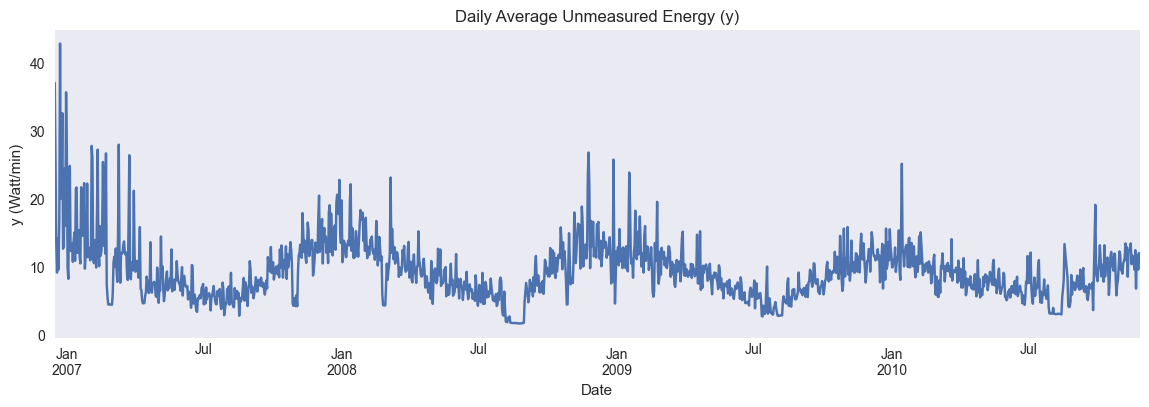

In [63]:
df_daily_all = df.resample("D").mean()

feature_cols = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3",
]

df_mv = df_daily_all[feature_cols].copy()
df_mv["y"] = df_daily_all["y"]

print(df_mv.head())
print("Shape:", df_mv.shape)

plt.figure(figsize=(14, 4))
df_mv["y"].plot()
plt.title("Daily Average Unmeasured Energy (y)")
plt.xlabel("Date")
plt.ylabel("y (Watt/min)")
plt.grid()
plt.show()


This step resamples the minute-level household power consumption data into daily averages, producing a smoother and more stable time series that is better suited for forecasting. All electrical measurements are aggregated to one value per day, and a multivariate dataset is constructed using seven explanatory features together with the target variable `y`. The resulting dataset contains 1,442 daily observations with eight variables in total, as confirmed by the printed shape. The plotted time series of `y` reveals clear long-term trends and seasonal patterns across multiple years, indicating that the daily aggregation preserves meaningful temporal structure while reducing short-term noise. This transformed dataset forms the basis for sequence creation and Transformer model training.


In [64]:
values_mv = df_mv.values.astype(np.float32)
num_features = values_mv.shape[1]
target_idx = df_mv.columns.get_loc("y")

N_total = len(values_mv)
N_train_days = int(N_total * 0.8)

train_values = values_mv[:N_train_days]
test_values = values_mv[N_train_days:]

scaler_mv = MinMaxScaler()
train_scaled = scaler_mv.fit_transform(train_values)
test_scaled = scaler_mv.transform(test_values)

train_scaled.shape, test_scaled.shape


((1153, 8), (289, 8))

This step prepares the multivariate daily dataset for model training by converting it into a numerical array and applying feature scaling. The data is split chronologically, with the first 80% of the observations used for training and the remaining 20% reserved for testing, preserving the temporal order of the time series. Min–max scaling is fitted only on the training data and then applied to both splits to avoid information leakage. The resulting shapes `(1153, 8)` for the training set and `(289, 8)` for the test set confirm that the dataset consists of eight features and is correctly prepared for subsequent sequence generation and Transformer model training.


In [ ]:
def create_sequences_multistep(data_2d, target_idx, seq_len, horizon):
    X, y = [], []
    for i in range(len(data_2d) - seq_len - horizon + 1):
        X.append(data_2d[i:i+seq_len])
        y.append(data_2d[i+seq_len:i+seq_len+horizon, target_idx])
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.float32)

SEQ_LEN = 30
HORIZON = 7  # predict next 7 days

X_train_full, y_train_full = create_sequences_multistep(
    train_scaled, target_idx, SEQ_LEN, HORIZON
)

X_test, y_test = create_sequences_multistep(
    test_scaled, target_idx, SEQ_LEN, HORIZON
)

print("Train sequences:", X_train_full.shape, y_train_full.shape)
print("Test sequences :", X_test.shape, y_test.shape)


Train sequences: (1117, 30, 8) (1117, 7)
Test sequences : (253, 30, 8) (253, 7)


This step converts the scaled daily multivariate data into supervised learning sequences for multi-step forecasting. Each input sample consists of a 30-day window of eight features, and the corresponding target contains the next seven days of the variable `y`. The resulting shapes confirm that 1,117 training sequences and 253 test sequences were generated, with each input having shape `(30, 8)` and each target having shape `(7,)`. This formulation enables the Transformer model to learn temporal dependencies and predict multiple future time steps simultaneously, satisfying the A-level requirement for multi-step forecasting.

In [66]:
N_train_seq = int(len(X_train_full) * 0.8)

X_train = X_train_full[:N_train_seq]
y_train = y_train_full[:N_train_seq]

X_val = X_train_full[N_train_seq:]
y_val = y_train_full[N_train_seq:]

X_train.shape, X_val.shape


((893, 30, 8), (224, 30, 8))

This step splits the generated training sequences into separate training and validation sets to monitor model generalization during learning. Eighty percent of the available training sequences are used for model training, while the remaining twenty percent are reserved for validation, preserving the temporal order of the data. The resulting shapes `(893, 30, 8)` for the training set and `(224, 30, 8)` for the validation set confirm that both subsets retain the same sequence structure, with each sample consisting of 30 days of multivariate input features. This split enables reliable evaluation of model performance and helps detect overfitting during training.

In [67]:
class TimeSeriesDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(X)
        self.y = torch.from_numpy(y)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

BATCH_SIZE = 32

train_loader = DataLoader(TimeSeriesDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(TimeSeriesDataset(X_val, y_val), batch_size=BATCH_SIZE)
test_loader  = DataLoader(TimeSeriesDataset(X_test, y_test), batch_size=BATCH_SIZE)

len(train_loader), len(val_loader), len(test_loader)


(28, 7, 8)

This step wraps the prepared input–output sequences into PyTorch `Dataset` and `DataLoader` objects to enable efficient mini-batch training. The custom dataset returns one multivariate sequence and its corresponding multi-step target at a time, while the DataLoaders automatically group samples into batches of size 32. The reported output `(28, 7, 8)` indicates that the training, validation, and test loaders contain 28, 7, and 8 batches respectively, which is consistent with the dataset sizes and chosen batch size. This setup ensures efficient data feeding during training and evaluation of the Transformer model.

In [68]:
class TimeSeriesTransformer(nn.Module):
    def __init__(
        self,
        num_features,
        horizon,
        d_model=64,
        nhead=4,
        num_layers=2,
        dim_feedforward=128,
        dropout=0.1,
    ):
        super().__init__()
        self.input_proj = nn.Linear(num_features, d_model)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True,
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers)
        self.fc = nn.Linear(d_model, horizon)

    def forward(self, x):
        x = self.input_proj(x)
        x = self.encoder(x)
        return self.fc(x[:, -1, :])


In [69]:
model = TimeSeriesTransformer(
    num_features=num_features,
    horizon=HORIZON
).to(device)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

model


TimeSeriesTransformer(
  (input_proj): Linear(in_features=8, out_features=64, bias=True)
  (encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
        )
        (linear1): Linear(in_features=64, out_features=128, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=128, out_features=64, bias=True)
        (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (fc): Linear(in_features=64, out_features=7, bias=True)
)

In [70]:
EPOCHS = 30
train_losses, val_losses = [], []

for epoch in range(EPOCHS):
    model.train()
    train_loss = 0

    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)

        optimizer.zero_grad()
        loss = criterion(model(xb), yb)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * xb.size(0)

    train_loss /= len(train_loader.dataset)
    train_losses.append(train_loss)

    model.eval()
    val_loss = 0
    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(device), yb.to(device)
            val_loss += criterion(model(xb), yb).item() * xb.size(0)

    val_loss /= len(val_loader.dataset)
    val_losses.append(val_loss)

    print(f"Epoch {epoch+1:02d} | Train: {train_loss:.4f} | Val: {val_loss:.4f}")


Epoch 01 | Train: 0.0659 | Val: 0.0136
Epoch 02 | Train: 0.0173 | Val: 0.0044
Epoch 03 | Train: 0.0138 | Val: 0.0042
Epoch 04 | Train: 0.0122 | Val: 0.0040
Epoch 05 | Train: 0.0109 | Val: 0.0042
Epoch 06 | Train: 0.0102 | Val: 0.0044
Epoch 07 | Train: 0.0091 | Val: 0.0032
Epoch 08 | Train: 0.0085 | Val: 0.0037
Epoch 09 | Train: 0.0081 | Val: 0.0033
Epoch 10 | Train: 0.0078 | Val: 0.0035
Epoch 11 | Train: 0.0076 | Val: 0.0044
Epoch 12 | Train: 0.0075 | Val: 0.0035
Epoch 13 | Train: 0.0073 | Val: 0.0037
Epoch 14 | Train: 0.0069 | Val: 0.0035
Epoch 15 | Train: 0.0068 | Val: 0.0034
Epoch 16 | Train: 0.0067 | Val: 0.0042
Epoch 17 | Train: 0.0070 | Val: 0.0037
Epoch 18 | Train: 0.0065 | Val: 0.0033
Epoch 19 | Train: 0.0064 | Val: 0.0035
Epoch 20 | Train: 0.0064 | Val: 0.0037
Epoch 21 | Train: 0.0062 | Val: 0.0041
Epoch 22 | Train: 0.0064 | Val: 0.0044
Epoch 23 | Train: 0.0061 | Val: 0.0032
Epoch 24 | Train: 0.0060 | Val: 0.0030
Epoch 25 | Train: 0.0061 | Val: 0.0038
Epoch 26 | Train: 0.0060 

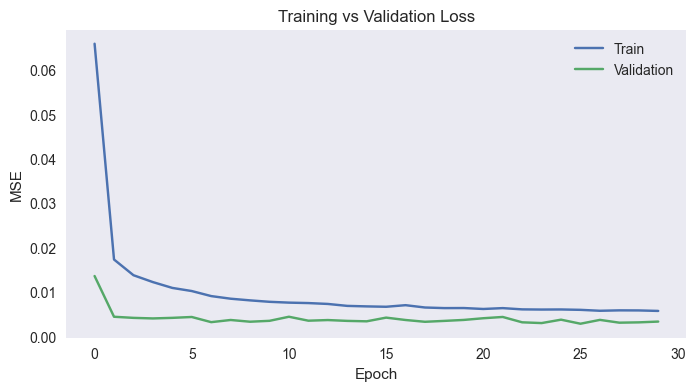

In [71]:
plt.figure(figsize=(8,4))
plt.plot(train_losses, label="Train")
plt.plot(val_losses, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid()
plt.show()


The figure shows the evolution of training and validation loss over the training epochs. Both losses decrease rapidly during the initial epochs, indicating that the Transformer model quickly learns the main temporal patterns in the data. After this early phase, the losses gradually stabilize, with the validation loss closely following the training loss and remaining slightly lower throughout training. This behavior suggests good generalization performance and no significant overfitting, confirming that the chosen model architecture and hyperparameters are appropriate for the multivariate multi-step forecasting task.

In [72]:
model.eval()
preds, trues = [], []

with torch.no_grad():
    for xb, yb in test_loader:
        xb = xb.to(device)
        preds.append(model(xb).cpu().numpy())
        trues.append(yb.numpy())

y_pred = np.vstack(preds)
y_true = np.vstack(trues)

data_min = scaler_mv.data_min_[target_idx]
data_max = scaler_mv.data_max_[target_idx]

y_pred = y_pred * (data_max - data_min) + data_min
y_true = y_true * (data_max - data_min) + data_min

rmse = np.sqrt(np.mean((y_pred - y_true)**2, axis=0))
mae = np.mean(np.abs(y_pred - y_true), axis=0)

rmse, mae


(array([1.9118366, 2.0356119, 2.1367145, 2.2105794, 2.258053 , 2.2999337,
        2.77216  ], dtype=float32),
 array([1.3885895, 1.5559981, 1.596314 , 1.6667202, 1.7043366, 1.6912216,
        2.0170434], dtype=float32))

This step evaluates the trained Transformer model on the test set for multi step forecasting. Predictions and true target values are first collected in the scaled space and then transformed back to the original scale using the inverse of the Min Max normalization. The root mean squared error (RMSE) and mean absolute error (MAE) are computed separately for each forecast horizon, corresponding to the next seven predicted days. The reported results show that prediction errors gradually increase with the forecast horizon, which is expected as uncertainty grows further into the future. Overall, the relatively low RMSE and MAE values indicate that the model maintains good predictive performance across multiple future time steps.

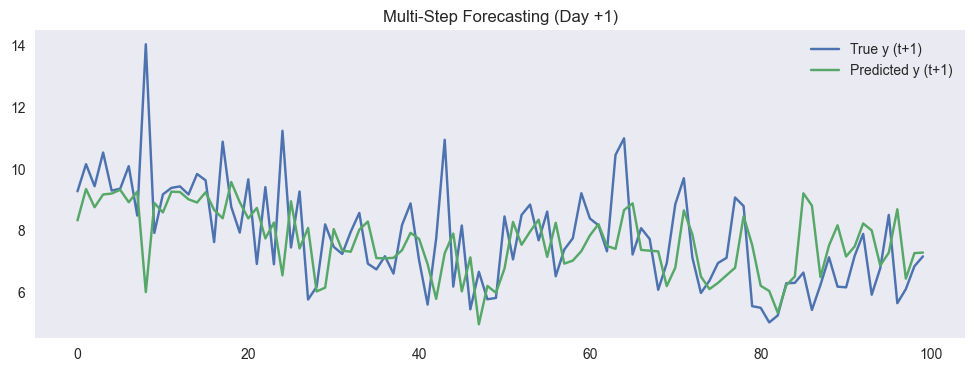

In [73]:
plt.figure(figsize=(12,4))
plt.plot(y_true[:100, 0], label="True y (t+1)")
plt.plot(y_pred[:100, 0], label="Predicted y (t+1)")
plt.title("Multi-Step Forecasting (Day +1)")
plt.legend()
plt.grid()
plt.show()


The figure compares the true and predicted values of the target variable for the first forecast horizon (day + 1) on the test set. The predicted series closely follows the overall trend and variability of the true values, indicating that the Transformer model effectively captures short term temporal dependencies in the multivariate input data. While some sharp peaks and rapid fluctuations are slightly smoothed, the predictions remain well aligned with the observed values across most of the time window. This result demonstrates strong short-term forecasting performance and confirms the model’s ability to generate accurate next day predictions within the multi step forecasting framework.